# Teeth Classification

This notebook covers:

- Environment & dependencies  
- Dataset inspection & visualization  
- Preprocessing & augmentations  
- From-scratch CNN model definition and training  
- Evaluation with confusion matrix and misclassified examples  
- Saving the best model, predictions, and training history  


In [1]:
import os
import random
import math
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import cv2


import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, WeightedRandomSampler
from torchvision import transforms, datasets

from sklearn.metrics import confusion_matrix, classification_report
from tqdm.auto import tqdm

# TensorBoard
from torch.utils.tensorboard import SummaryWriter
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)
print('Imports done')

c:\Users\Eng.Razan\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: cuda
Imports done


## Datasets and DataLoaders
We use `ImageFolder`. To mitigate class imbalance we provide both options:
- Oversampling via `WeightedRandomSampler` (used by default)
- Using class weights in the loss function (optional)


In [16]:
ROOT = Path('..')
data_dir = ROOT / 'data' / 'Teeth_Dataset'
IMG_SIZE = 224  

# Compute mean/std directly from train_dataset (subset for speed)
def compute_mean_std(dataset, sample_size=400):
    idxs = random.sample(range(len(dataset)), min(sample_size, len(dataset)))
    means, stds = [], []
    for i in tqdm(idxs, desc="Computing mean/std"):
        img, _ = dataset[i]
        arr = np.array(transforms.ToPILImage()(img)).astype(np.float32)/255.0
        means.append(arr.mean(axis=(0,1)))
        stds.append(arr.std(axis=(0,1)))
    mean = np.mean(means, axis=0)
    std = np.mean(stds, axis=0)
    return mean.tolist(), std.tolist()

try:
    mean, std = compute_mean_std(train_dataset, sample_size=400)
except Exception as e:
    print("Failed to compute mean/std — falling back to ImageNet values:", e)
    mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

print("Using mean:", mean)
print("Using std:", std)


transform_train = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

transform_test = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

train_dataset = datasets.ImageFolder(os.path.join(data_dir, "Training"), transform=transform_train)
val_dataset = datasets.ImageFolder(os.path.join(data_dir, "Validation"), transform=transform_test)
test_dataset = datasets.ImageFolder(os.path.join(data_dir, "Testing"), transform=transform_test)


# Denormalize helper
def denormalize(tensor_img):
    img = tensor_img.clone()
    for t, m, s in zip(img, mean, std):
        t.mul_(s).add_(m)
    return torch.clamp(img, 0, 1)

print("Transforms ready")
print("Classes:", train_dataset.classes)
print("Number of training samples:", len(train_dataset))
print("Number of validation samples:", len(val_dataset))
print("Number of testing samples:", len(test_dataset))


Computing mean/std: 100%|██████████| 400/400 [00:01<00:00, 356.66it/s]

Using mean: [0.47365978360176086, 0.5072661638259888, 0.4893795847892761]
Using std: [0.2911527752876282, 0.29588305950164795, 0.2806512713432312]
Transforms ready
Classes: ['CaS', 'CoS', 'Gum', 'MC', 'OC', 'OLP', 'OT']
Number of training samples: 3087
Number of validation samples: 1028
Number of testing samples: 1508


## GPU memory check & recommended batch size
This cell checks the GPU memory and prints a conservative recommended batch size.


In [15]:
def recommend_batch_size(img_size=IMG_SIZE, safety_factor=0.7, base_per_image_gb=0.12):
    """
    Heuristic recommendation for batch size based on GPU memory.
    - base_per_image_gb: rough GB per image including activations/gradients for a moderate model at 224x224 (default 0.12 GB ~120MB)
    - safety_factor: fraction of total GPU memory we'll use to leave room for others (0.7 default)
    Returns (total_mem_gb, recommended_batch)
    """
    if not torch.cuda.is_available():
        return 0.0, 4
    prop = torch.cuda.get_device_properties(0)
    total_mem_gb = prop.total_memory / (1024**3)
    # scale base per image with image area relative to 224
    scale = (img_size / 224) ** 2
    per_image = base_per_image_gb * scale
    avail = total_mem_gb * safety_factor
    rec = int(avail / per_image)
    rec = max(4, min(rec, 256))
    return total_mem_gb, rec

total_mem_gb, rec_bs = recommend_batch_size()
print(f'Total GPU memory (GB): {total_mem_gb:.2f}')
print(f'Recommended starting batch size (heuristic): {rec_bs}')
print('Note: This is an estimate. Monitor actual GPU memory (nvidia-smi) and lower batch size if CUDA OOM occurs.')

Total GPU memory (GB): 4.00
Recommended starting batch size (heuristic): 23
Note: This is an estimate. Monitor actual GPU memory (nvidia-smi) and lower batch size if CUDA OOM occurs.


## Dataset quick inspection
This cell will count images per class for Training / Validation / Testing and show a bar plot of the training distribution.

Train class counts: {'CaS': 480, 'CoS': 450, 'Gum': 360, 'MC': 540, 'OC': 324, 'OLP': 540, 'OT': 393}
Val class counts: {'CaS': 160, 'CoS': 149, 'Gum': 120, 'MC': 180, 'OC': 108, 'OLP': 180, 'OT': 131}
Test class counts: {'CaS': 160, 'CoS': 149, 'Gum': 120, 'MC': 180, 'OC': 108, 'OLP': 180, 'OT': 131, 'out': 160, 'output': 160, 'outputs': 160}


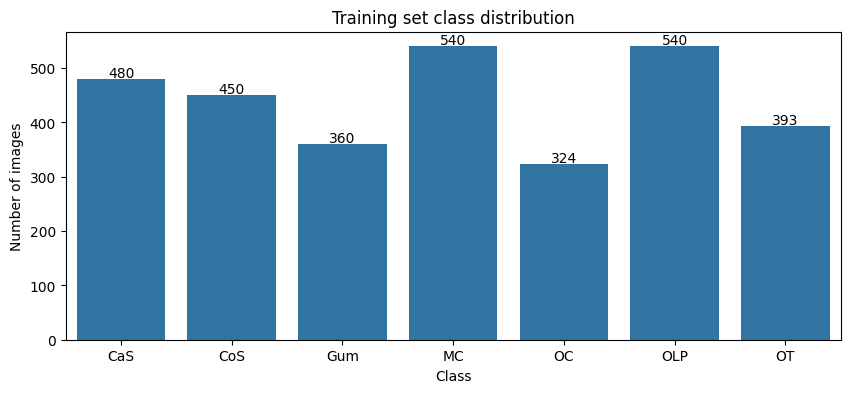

In [16]:
from collections import Counter

def get_class_counts_from_dataset(dataset):
    counts = Counter([dataset.classes[y] for _, y in dataset])
    return dict(counts)

train_counts = get_class_counts_from_dataset(train_dataset)
val_counts = get_class_counts_from_dataset(val_dataset)
test_counts = get_class_counts_from_dataset(test_dataset)

print('Train class counts:', train_counts)
print('Val class counts:', val_counts)
print('Test class counts:', test_counts)

# Plot training set distribution
if train_counts:
    names = list(train_counts.keys())
    vals = [train_counts[n] for n in names]
    plt.figure(figsize=(10,4))
    sns.barplot(x=names, y=vals)
    plt.title('Training set class distribution')
    plt.ylabel('Number of images')
    plt.xlabel('Class')
    for i, v in enumerate(vals):
        plt.text(i, v+3, str(v), ha='center')
    plt.show()


## Visual examples — samples per class
Shows a small grid of raw images (unaugmented) per class.

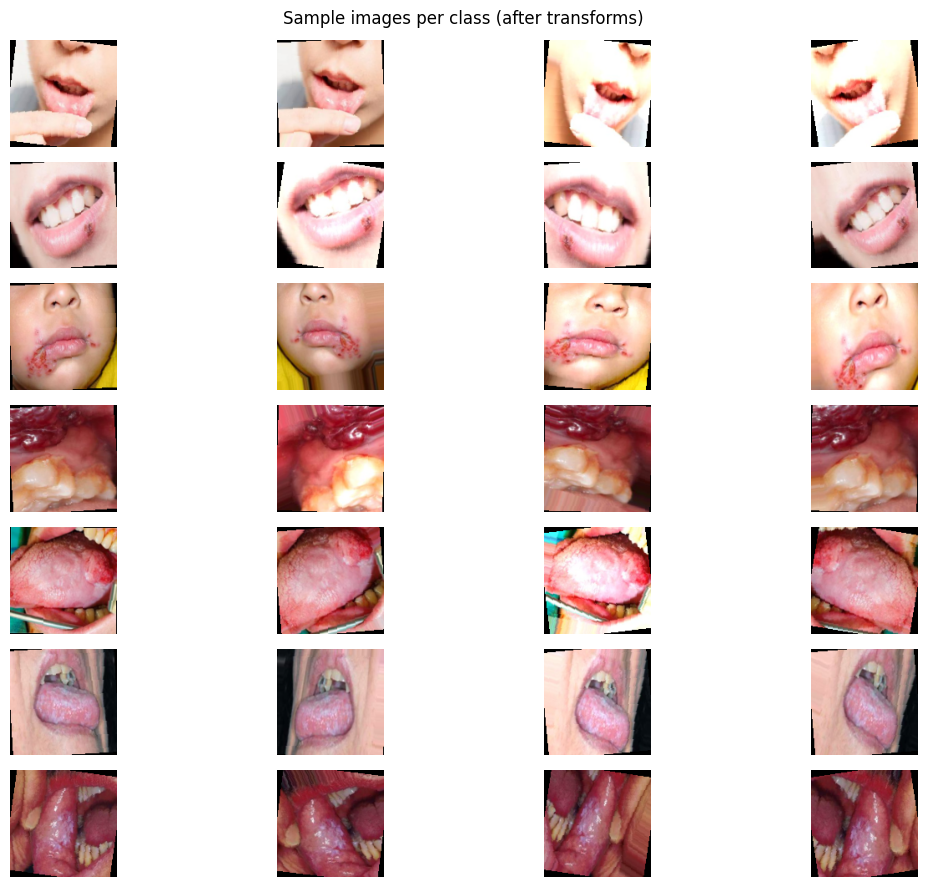

In [9]:
def show_samples_per_class(dataset, n=4, figsize=(12,9)):
    classes = dataset.classes
    idxs_by_class = {cls: [] for cls in classes}
    
    for i, (_, y) in enumerate(dataset):
        cls = classes[y]
        if len(idxs_by_class[cls]) < n:
            idxs_by_class[cls].append(i)
        if all(len(v) >= n for v in idxs_by_class.values()):
            break

    fig, axes = plt.subplots(len(classes), n, figsize=figsize)
    for i, cls in enumerate(classes):
        for j, idx in enumerate(idxs_by_class[cls]):
            img, _ = dataset[idx]
            img = img.permute(1,2,0).numpy()
            img = (img - img.min()) / (img.max() - img.min())
            ax = axes[i, j] if len(classes) > 1 else axes[j]
            ax.imshow(img)
            ax.axis("off")
        axes[i,0].set_ylabel(cls, fontsize=11)
    plt.suptitle('Sample images per class (after transforms)')
    plt.tight_layout()
    plt.show()

show_samples_per_class(train_dataset, n=4)


## Preprocessing & Augmentation
We compute dataset mean/std (sample-based) and define two transform pipelines:
- transform_train: stronger augmentations

### Before and after augmentation — visual check
Run this to inspect how augmentations change samples. Useful to ensure augmentations don't break the diagnostically relevant features.

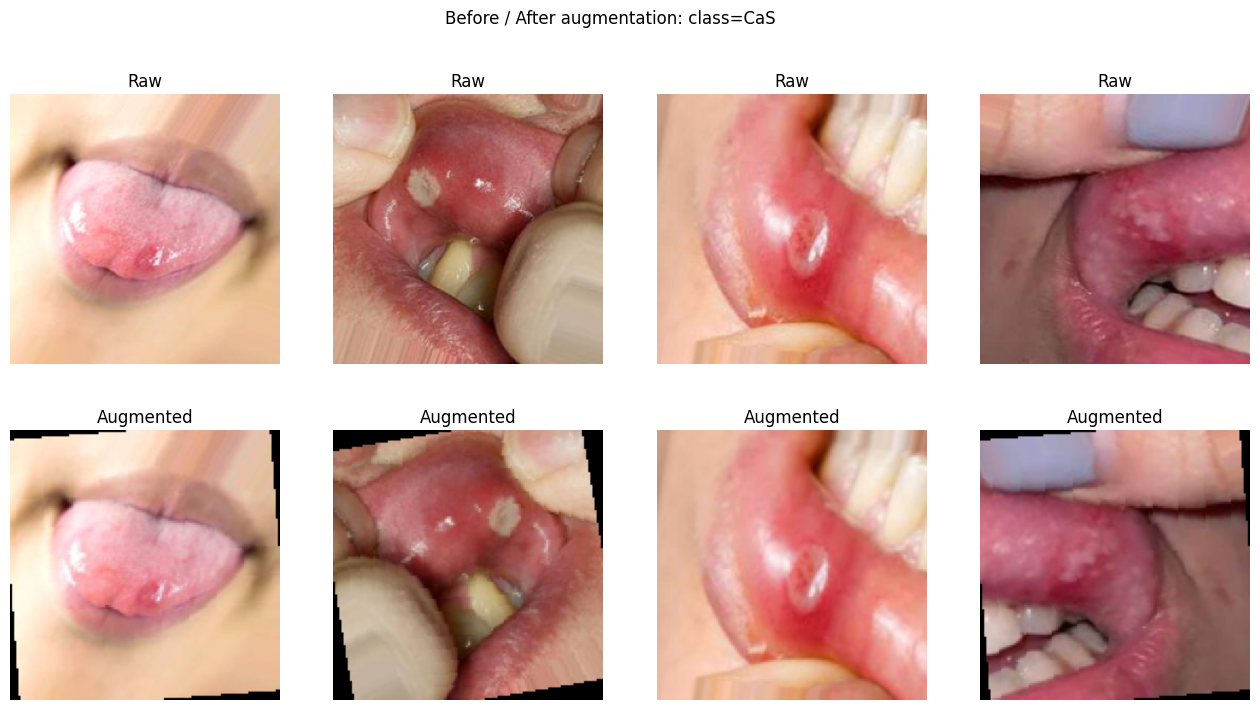

In [3]:
def show_before_after(dataset, cls_idx, n=4):
    cls_name = dataset.classes[cls_idx]
    idxs = [i for i, (_, y) in enumerate(dataset.samples) if y == cls_idx]
    random.shuffle(idxs)
    idxs = idxs[:n]

    fig, axes = plt.subplots(2, n, figsize=(4*n, 8))
    for i, idx in enumerate(idxs):
        path, _ = dataset.samples[idx]
        raw = Image.open(path).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
        axes[0,i].imshow(raw); axes[0,i].axis("off"); axes[0,i].set_title("Raw")

        aug = transform_train(raw)
        aug = denormalize(aug)
        axes[1,i].imshow(np.transpose(aug.numpy(), (1,2,0)))
        axes[1,i].axis("off"); axes[1,i].set_title("Augmented")

    plt.suptitle(f"Before / After augmentation: class={cls_name}")
    plt.show()

# Show for the first class
show_before_after(train_dataset, cls_idx=0, n=4)


## DataLoaders

- Oversampling via `WeightedRandomSampler` (used by default)
- Using class weights in the loss function (optional)


In [4]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# --- Handle imbalance with WeightedRandomSampler ---
train_targets = [y for _, y in train_dataset.samples]
class_sample_counts = np.array([train_targets.count(i) for i in range(len(train_dataset.classes))])
weights = 1.0 / class_sample_counts
samples_weights = np.array([weights[t] for t in train_targets])
sampler = WeightedRandomSampler(samples_weights, num_samples=len(samples_weights), replacement=True)


class_weights = torch.tensor([1.0/count for count in class_sample_counts], dtype=torch.float32).to(DEVICE)

print("Classes:", train_dataset.classes)
print("Per-class sample counts:", class_sample_counts)
print("Train loader batches:", len(train_loader))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))
print("Class weights (use with CrossEntropyLoss):", class_weights)

Classes: ['CaS', 'CoS', 'Gum', 'MC', 'OC', 'OLP', 'OT']
Per-class sample counts: [480 450 360 540 324 540 393]
Train loader batches: 97
Validation samples: 1028
Test samples: 1508
Class weights (use with CrossEntropyLoss): tensor([0.0021, 0.0022, 0.0028, 0.0019, 0.0031, 0.0019, 0.0025],
       device='cuda:0')


## Model (from-scratch)

In [20]:
# --- Model definition ---
class BasicBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3,
                               stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3,
                               stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)

        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1,
                          stride=stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += self.shortcut(x)
        return self.relu(out)

class TinyResNet(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()
        self.layer1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True)
        )
        self.layer2 = self._make_layer(32, 64, stride=2)
        self.layer3 = self._make_layer(64, 128, stride=2)
        self.layer4 = self._make_layer(128, 256, stride=2)
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(256, num_classes)

    def _make_layer(self, in_channels, out_channels, stride):
        return nn.Sequential(
            BasicBlock(in_channels, out_channels, stride),
            BasicBlock(out_channels, out_channels, 1)
        )

    def forward(self, x):
        out = self.layer1(x)
        out = self.layer2(out)
        out = self.layer3(out)
        out = self.layer4(out)
        out = self.avgpool(out)
        out = torch.flatten(out, 1)
        return self.fc(out)

# Instantiate with the correct number of classes
model = TinyResNet(num_classes=len(train_dataset.classes))
model = model.to(DEVICE)

# Print param count
print(f"Model has {sum(p.numel() for p in model.parameters() if p.requires_grad):,} trainable parameters")


Model has 2,759,719 trainable parameters


## Training loop
# Training utilities: optimizer, loss, TensorBoard logging, checkpointing
This cell sets up `CrossEntropyLoss` (with class weights optional), the optimizer and utility functions for train/validate. Checkpoints are saved every `SAVE_EVERY` epochs and best model is saved separately.

In [28]:

optimizer = optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()
NUM_EPOCHS = 50
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

best_val_acc = 0

for epoch in range(1, NUM_EPOCHS+1):
    model.train()
    running_loss, correct, total = 0, 0, 0
    for xb, yb in tqdm(train_loader, desc=f"Train Epoch {epoch}/{NUM_EPOCHS}"):
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        out = model(xb)
        loss = criterion(out, yb)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()*xb.size(0)
        _, pred = out.max(1)
        correct += pred.eq(yb).sum().item()
        total += yb.size(0)
    train_loss = running_loss/total
    train_acc = correct/total

    # validation
    model.eval()
    val_loss, val_correct, val_total = 0, 0, 0
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            out = model(xb)
            loss = criterion(out, yb)
            val_loss += loss.item()*xb.size(0)
            _, pred = out.max(1)
            val_correct += pred.eq(yb).sum().item()
            val_total += yb.size(0)
    val_loss /= val_total
    val_acc = val_correct/val_total

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(f"Epoch {epoch}: train_loss={train_loss:.4f}, train_acc={train_acc:.4f} | val_loss={val_loss:.4f}, val_acc={val_acc:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "best_model.pth")
        print("  Saved new best model!")

print("Training finished. Best val acc:", best_val_acc)


Train Epoch 1/50: 100%|██████████| 97/97 [00:15<00:00,  6.26it/s]


Epoch 1: train_loss=1.7637, train_acc=0.2961 | val_loss=1.6374, val_acc=0.3570
  Saved new best model!


Train Epoch 2/50: 100%|██████████| 97/97 [00:14<00:00,  6.58it/s]


Epoch 2: train_loss=1.6094, train_acc=0.3670 | val_loss=1.4987, val_acc=0.4037
  Saved new best model!


Train Epoch 3/50: 100%|██████████| 97/97 [00:14<00:00,  6.65it/s]


...

Epoch 48: train_loss=0.0594, train_acc=0.9783 | val_loss=0.1428, val_acc=0.9523


Train Epoch 49/50: 100%|██████████| 97/97 [00:14<00:00,  6.70it/s]


Epoch 49: train_loss=0.1428, train_acc=0.9514 | val_loss=0.1520, val_acc=0.9484


Train Epoch 50/50: 100%|██████████| 97/97 [00:14<00:00,  6.52it/s]


Epoch 50: train_loss=0.0977, train_acc=0.9666 | val_loss=0.0814, val_acc=0.9689
Training finished. Best val acc: 0.9795719844357976


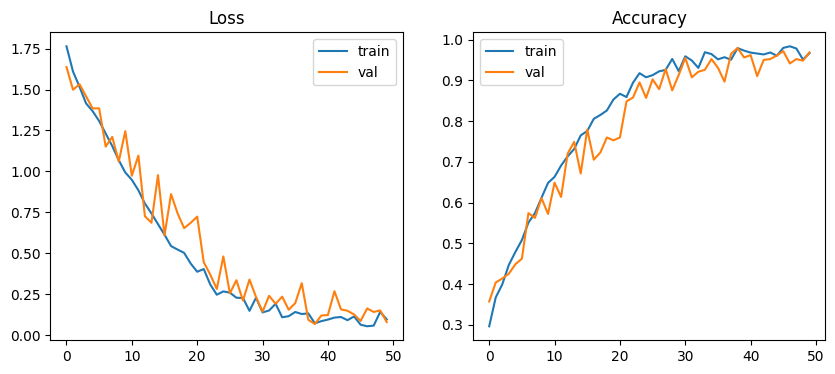

In [29]:

plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.plot(history['train_loss'], label='train'); plt.plot(history['val_loss'], label='val'); plt.title('Loss'); plt.legend()
plt.subplot(1,2,2); plt.plot(history['train_acc'], label='train'); plt.plot(history['val_acc'], label='val'); plt.title('Accuracy'); plt.legend()
plt.show()


## Evaluation on test set
Loads best model and evaluates on test set, prints classification report and confusion matrix.

C:\Users\Eng.Razan\AppData\Local\Temp\ipykernel_10892\359270813.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("best_model.pth", map_lo

              precision    recall  f1-score   support

         CaS       0.99      0.97      0.98       160
         CoS       0.97      0.99      0.98       149
         Gum       0.98      0.99      0.99       120
          MC       0.95      0.98      0.96       180
          OC       0.96      0.94      0.95       108
         OLP       0.98      0.95      0.97       180
          OT       0.98      0.99      0.98       131

    accuracy                           0.97      1028
   macro avg       0.97      0.97      0.97      1028
weighted avg       0.97      0.97      0.97      1028



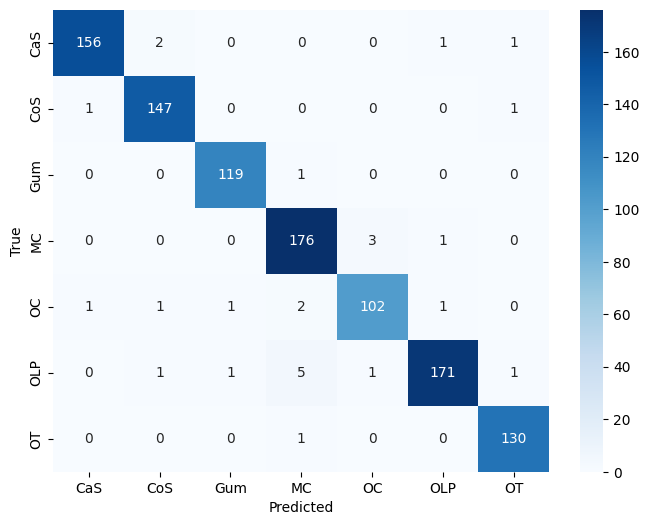

In [30]:
# Load model
model.load_state_dict(torch.load("best_model.pth", map_location=DEVICE))
model.eval()

# Classes to ignore
ignore_classes = {"out", "output", "outputs"}
valid_class_indices = [i for i, cls in enumerate(test_dataset.classes) if cls not in ignore_classes]

# Filtered class names
filtered_classes = [cls for cls in test_dataset.classes if cls not in ignore_classes]

y_true, y_pred = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        out = model(xb)
        _, pred = out.max(1)

        # keep only valid class samples
        mask = torch.isin(yb.cpu(), torch.tensor(valid_class_indices))
        y_true.extend(yb.cpu()[mask].numpy())
        y_pred.extend(pred.cpu()[mask].numpy())

# Remap labels to filtered class indices
mapping = {old_idx: new_idx for new_idx, old_idx in enumerate(valid_class_indices)}
y_true = [mapping[i] for i in y_true]
y_pred = [mapping[i] for i in y_pred]

# Evaluation
print(classification_report(y_true, y_pred, target_names=filtered_classes))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=filtered_classes, yticklabels=filtered_classes)
plt.xlabel("Predicted"); plt.ylabel("True")
plt.show()


## Grad-Cam

c:\Users\Eng.Razan\AppData\Local\Programs\Python\Python310\lib\site-packages\torch\nn\modules\module.py:1827: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


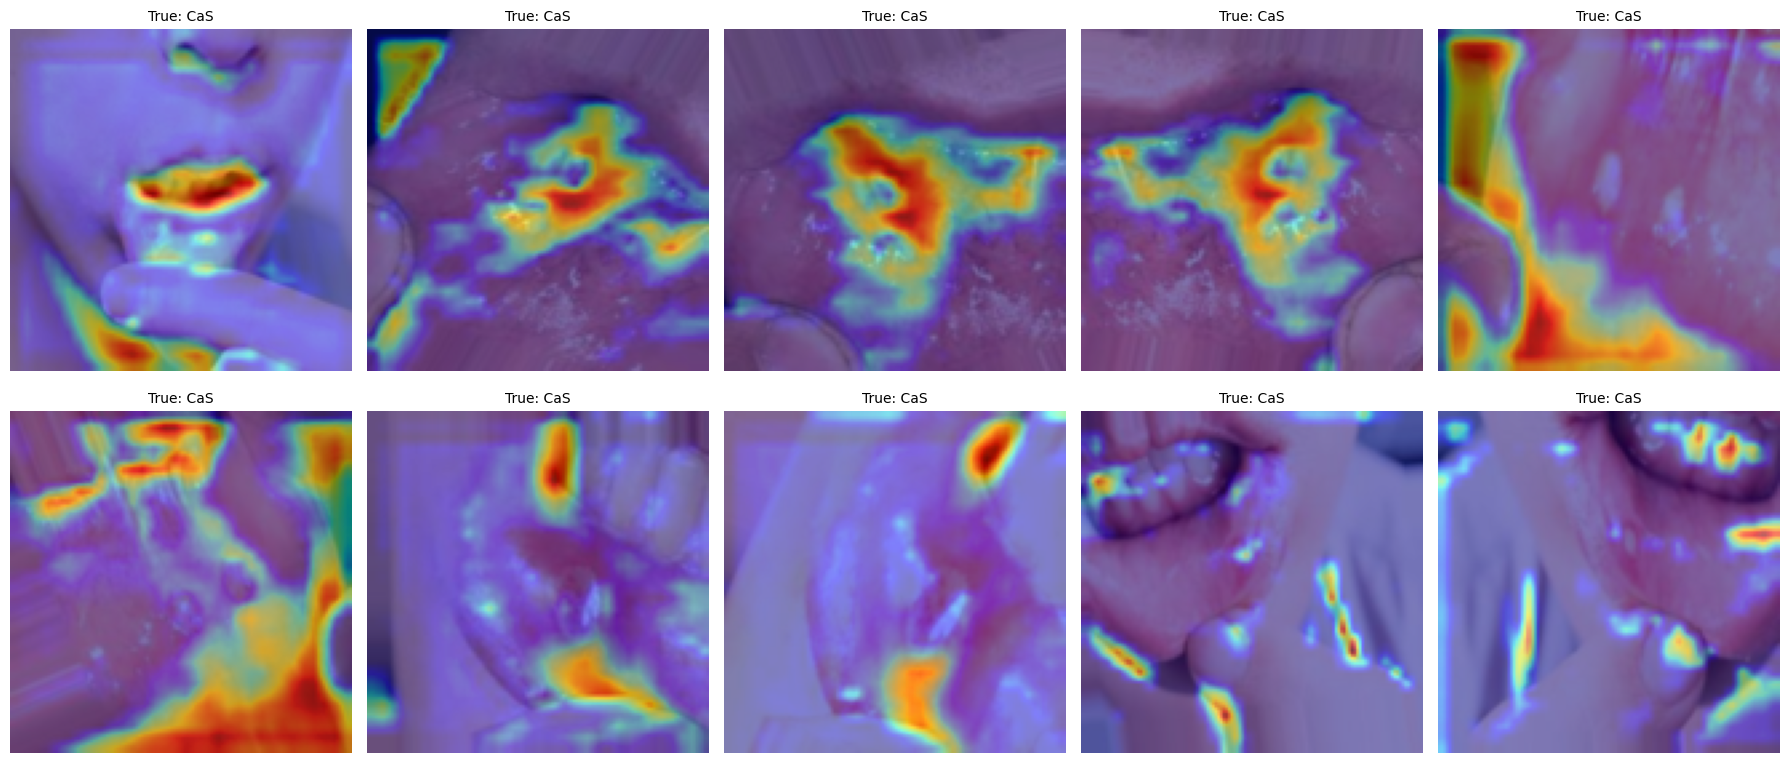

In [40]:

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        target_layer.register_forward_hook(self.save_activation)
        target_layer.register_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def __call__(self, x, class_idx=None):
        self.model.zero_grad()
        out = self.model(x)
        if class_idx is None:
            class_idx = out.argmax(dim=1)
        loss = out[:, class_idx]
        loss.backward(torch.ones_like(loss))
        grads = self.gradients
        acts = self.activations
        weights = grads.mean(dim=(2,3), keepdim=True)
        cam = (weights*acts).sum(dim=1, keepdim=True)
        cam = F.relu(cam)
        cam = F.interpolate(cam, size=x.shape[2:], mode="bilinear", align_corners=False)
        cam = cam.squeeze().cpu().detach().numpy()
        cam = (cam - cam.min())/(cam.max()-cam.min()+1e-8)
        return cam

gradcam = GradCAM(model, model.layer3)


# Grad-CAM visualization for multiple samples
xb, yb = next(iter(test_loader))
xb, yb = xb.to(DEVICE), yb.to(DEVICE)

num_images = 10   # total images to show
rows, cols = 2, 5  # arrange in 2 rows, 5 per row

plt.figure(figsize=(18, 8))

for i in range(num_images):
    cam = gradcam(xb[i:i+1])  # single sample
    img = xb[i].permute(1, 2, 0).cpu().numpy()
    img = (img - img.min()) / (img.max() - img.min())

    plt.subplot(rows, cols, i+1)
    plt.imshow(img)
    plt.imshow(cam, cmap="jet", alpha=0.5)
    plt.title(f"True: {test_dataset.classes[yb[i]]}", fontsize=10)
    plt.axis("off")

plt.tight_layout()
plt.show()


## Final Notes & Saved Artifacts

- Best model: **`best_model.pth`**  
- Test predictions: **`test_preds.npy`**  
- Test targets: **`test_targets.npy`**  
- Training history: **`history.json`**

These files can be reused later for evaluation, visualization, or further training.


In [36]:
# Final notes & saving artifacts
print("Best model saved as: best_model.pth")

# Save predictions
try:
    np.save("test_preds.npy", y_pred)
    np.save("test_targets.npy", y_true)
    print("Saved test predictions and targets as .npy files")
except Exception as e:
    print("No predictions to save:", e)

# Save training history
try:
    with open("history.json", "w") as f:
        json.dump(history, f)
    print("Saved training history as history.json")
except Exception as e:
    print("History not found or not available:", e)


Best model saved as: best_model.pth
Saved test predictions and targets as .npy files
Saved training history as history.json


## Setup

In [ ]:
import torchvision.models as models
import torch.nn as nn

NUM_CLASSES = len(train_dataset.classes)

def build_model(model_name, pretrained=True):
    if model_name == "resnet18":
        model = models.resnet18(pretrained=pretrained)
        model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)

    elif model_name == "resnet50":
        model = models.resnet50(pretrained=pretrained)
        model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)

    elif model_name == "mobilenet_v2":
        model = models.mobilenet_v2(pretrained=pretrained)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES)

    elif model_name == "efficientnet_b0":
        model = models.efficientnet_b0(pretrained=pretrained)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES)

    elif model_name == "densenet121":
        model = models.densenet121(pretrained=pretrained)
        model.classifier = nn.Linear(model.classifier.in_features, NUM_CLASSES)


    else:
        raise ValueError(f"Unknown model name: {model_name}")
    
    return model.to(DEVICE)


## Training & Evaluation Function (reuse for each model)

In [6]:
def train_and_evaluate(model, model_name, num_epochs=10):
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.CrossEntropyLoss()

    best_val_acc = 0
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(1, num_epochs+1):
        # ---- Training ----
        model.train()
        running_loss, correct, total = 0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            out = model(xb)
            loss = criterion(out, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()*xb.size(0)
            _, pred = out.max(1)
            correct += pred.eq(yb).sum().item()
            total += yb.size(0)
        train_loss = running_loss/total
        train_acc = correct/total

        # ---- Validation ----
        model.eval()
        val_loss, val_correct, val_total = 0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                out = model(xb)
                loss = criterion(out, yb)
                val_loss += loss.item()*xb.size(0)
                _, pred = out.max(1)
                val_correct += pred.eq(yb).sum().item()
                val_total += yb.size(0)
        val_loss /= val_total
        val_acc = val_correct/val_total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(f"[{model_name}] Epoch {epoch}: train_acc={train_acc:.4f}, val_acc={val_acc:.4f}")

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), f"{model_name}_best.pth")
            print(f"  🔥 Saved new best model: {model_name}_best.pth")

    print(f"[{model_name}] Training finished. Best val acc: {best_val_acc:.4f}")
    return history


In [9]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

def evaluate_model(model_name, model_path, dataset, loader):
    # Load model
    model = build_model(model_name, pretrained=False)  # same architecture
    model.load_state_dict(torch.load(model_path, map_location=DEVICE))
    model.to(DEVICE)
    model.eval()

    # Ignore irrelevant classes
    ignore_classes = {"out", "output", "outputs"}
    valid_class_indices = [i for i, cls in enumerate(dataset.classes) if cls not in ignore_classes]
    filtered_classes = [cls for cls in dataset.classes if cls not in ignore_classes]

    y_true, y_pred = [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            out = model(xb)
            _, pred = out.max(1)

            mask = torch.isin(yb.cpu(), torch.tensor(valid_class_indices))
            y_true.extend(yb.cpu()[mask].numpy())
            y_pred.extend(pred.cpu()[mask].numpy())

    # Remap indices
    mapping = {old_idx: new_idx for new_idx, old_idx in enumerate(valid_class_indices)}
    y_true = [mapping[i] for i in y_true]
    y_pred = [mapping[i] for i in y_pred]

    # Report
    acc = accuracy_score(y_true, y_pred)
    print(f"\n🔎 Evaluation for {model_name}:")
    print(f"Accuracy: {acc:.4f}")
    print(classification_report(y_true, y_pred, target_names=filtered_classes))

    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=filtered_classes, yticklabels=filtered_classes)
    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted"); plt.ylabel("True")
    plt.show()

    return acc


In [7]:
# ResNet18
model = build_model("resnet18")
history_resnet18 = train_and_evaluate(model, "resnet18", num_epochs=10)


c:\Users\Eng.Razan\AppData\Local\Programs\Python\Python310\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\Eng.Razan\AppData\Local\Programs\Python\Python310\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\Eng.Razan/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth
100%|██████████| 44.7M/44.7M [00:16<00:00, 2.90MB/s]


[resnet18] Epoch 1: train_acc=0.5986, val_acc=0.6323
  🔥 Saved new best model: resnet18_best.pth
[resnet18] Epoch 2: train_acc=0.8086, val_acc=0.7403
  🔥 Saved new best model: resnet18_best.pth
[resnet18] Epoch 3: train_acc=0.8448, val_acc=0.8337
  🔥 Saved new best model: resnet18_best.pth
[resnet18] Epoch 4: train_acc=0.8967, val_acc=0.8930
  🔥 Saved new best model: resnet18_best.pth
[resnet18] Epoch 5: train_acc=0.9223, val_acc=0.8872
[resnet18] Epoch 6: train_acc=0.9106, val_acc=0.8677
[resnet18] Epoch 7: train_acc=0.9388, val_acc=0.9562
  🔥 Saved new best model: resnet18_best.pth
[resnet18] Epoch 8: train_acc=0.9553, val_acc=0.9562
[resnet18] Epoch 9: train_acc=0.9446, val_acc=0.8103
[resnet18] Epoch 10: train_acc=0.9559, val_acc=0.9504
[resnet18] Training finished. Best val acc: 0.9562


In [8]:
# ResNet50
model = build_model("resnet50")
history_resnet50 = train_and_evaluate(model, "resnet50", num_epochs=10)


c:\Users\Eng.Razan\AppData\Local\Programs\Python\Python310\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


[resnet50] Epoch 1: train_acc=0.4593, val_acc=0.5730
  🔥 Saved new best model: resnet50_best.pth
[resnet50] Epoch 2: train_acc=0.6336, val_acc=0.6547
  🔥 Saved new best model: resnet50_best.pth
[resnet50] Epoch 3: train_acc=0.7470, val_acc=0.6790
  🔥 Saved new best model: resnet50_best.pth
[resnet50] Epoch 4: train_acc=0.7937, val_acc=0.7588
  🔥 Saved new best model: resnet50_best.pth
[resnet50] Epoch 5: train_acc=0.8455, val_acc=0.8356
  🔥 Saved new best model: resnet50_best.pth
[resnet50] Epoch 6: train_acc=0.8782, val_acc=0.8872
  🔥 Saved new best model: resnet50_best.pth
[resnet50] Epoch 7: train_acc=0.9080, val_acc=0.8619
[resnet50] Epoch 8: train_acc=0.9216, val_acc=0.9270
  🔥 Saved new best model: resnet50_best.pth
[resnet50] Epoch 9: train_acc=0.9362, val_acc=0.9047
[resnet50] Epoch 10: train_acc=0.9271, val_acc=0.8687
[resnet50] Training finished. Best val acc: 0.9270


In [10]:
# MobileNetV2
model = build_model("mobilenet_v2")
history_mobilenet = train_and_evaluate(model, "mobilenet_v2", num_epochs=10)


c:\Users\Eng.Razan\AppData\Local\Programs\Python\Python310\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to C:\Users\Eng.Razan/.cache\torch\hub\checkpoints\mobilenet_v2-b0353104.pth
100%|██████████| 13.6M/13.6M [00:05<00:00, 2.60MB/s]


[mobilenet_v2] Epoch 1: train_acc=0.6625, val_acc=0.8123
  🔥 Saved new best model: mobilenet_v2_best.pth
[mobilenet_v2] Epoch 2: train_acc=0.8397, val_acc=0.8735
  🔥 Saved new best model: mobilenet_v2_best.pth
[mobilenet_v2] Epoch 3: train_acc=0.8827, val_acc=0.8891
  🔥 Saved new best model: mobilenet_v2_best.pth
[mobilenet_v2] Epoch 4: train_acc=0.8879, val_acc=0.9154
  🔥 Saved new best model: mobilenet_v2_best.pth
[mobilenet_v2] Epoch 5: train_acc=0.9265, val_acc=0.9183
  🔥 Saved new best model: mobilenet_v2_best.pth
[mobilenet_v2] Epoch 6: train_acc=0.9310, val_acc=0.9543
  🔥 Saved new best model: mobilenet_v2_best.pth
[mobilenet_v2] Epoch 7: train_acc=0.9504, val_acc=0.9679
  🔥 Saved new best model: mobilenet_v2_best.pth
[mobilenet_v2] Epoch 8: train_acc=0.9446, val_acc=0.9222
[mobilenet_v2] Epoch 9: train_acc=0.9342, val_acc=0.9514
[mobilenet_v2] Epoch 10: train_acc=0.9511, val_acc=0.9572
[mobilenet_v2] Training finished. Best val acc: 0.9679


In [11]:
# EfficientNet-B0
model = build_model("efficientnet_b0")
history_effnet = train_and_evaluate(model, "efficientnet_b0", num_epochs=10)


c:\Users\Eng.Razan\AppData\Local\Programs\Python\Python310\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B0_Weights.IMAGENET1K_V1`. You can also use `weights=EfficientNet_B0_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to C:\Users\Eng.Razan/.cache\torch\hub\checkpoints\efficientnet_b0_rwightman-7f5810bc.pth
100%|██████████| 20.5M/20.5M [00:07<00:00, 2.76MB/s]


[efficientnet_b0] Epoch 1: train_acc=0.7512, val_acc=0.9095
  🔥 Saved new best model: efficientnet_b0_best.pth
[efficientnet_b0] Epoch 2: train_acc=0.9167, val_acc=0.9562
  🔥 Saved new best model: efficientnet_b0_best.pth
[efficientnet_b0] Epoch 3: train_acc=0.9316, val_acc=0.9669
  🔥 Saved new best model: efficientnet_b0_best.pth
[efficientnet_b0] Epoch 4: train_acc=0.9563, val_acc=0.9883
  🔥 Saved new best model: efficientnet_b0_best.pth
[efficientnet_b0] Epoch 5: train_acc=0.9647, val_acc=0.9844
[efficientnet_b0] Epoch 6: train_acc=0.9718, val_acc=0.9776
[efficientnet_b0] Epoch 7: train_acc=0.9534, val_acc=0.9737
[efficientnet_b0] Epoch 8: train_acc=0.9657, val_acc=0.9932
  🔥 Saved new best model: efficientnet_b0_best.pth
[efficientnet_b0] Epoch 9: train_acc=0.9754, val_acc=0.9874
[efficientnet_b0] Epoch 10: train_acc=0.9754, val_acc=0.9874
[efficientnet_b0] Training finished. Best val acc: 0.9932


In [12]:
# DenseNet121
model = build_model("densenet121")
history_densenet = train_and_evaluate(model, "densenet121", num_epochs=10)


c:\Users\Eng.Razan\AppData\Local\Programs\Python\Python310\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=DenseNet121_Weights.IMAGENET1K_V1`. You can also use `weights=DenseNet121_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to C:\Users\Eng.Razan/.cache\torch\hub\checkpoints\densenet121-a639ec97.pth
100%|██████████| 30.8M/30.8M [00:11<00:00, 2.90MB/s]


[densenet121] Epoch 1: train_acc=0.6667, val_acc=0.7315
  🔥 Saved new best model: densenet121_best.pth
[densenet121] Epoch 2: train_acc=0.8364, val_acc=0.8784
  🔥 Saved new best model: densenet121_best.pth
[densenet121] Epoch 3: train_acc=0.8691, val_acc=0.8842
  🔥 Saved new best model: densenet121_best.pth
[densenet121] Epoch 4: train_acc=0.9281, val_acc=0.9475
  🔥 Saved new best model: densenet121_best.pth
[densenet121] Epoch 5: train_acc=0.9504, val_acc=0.9339
[densenet121] Epoch 6: train_acc=0.9427, val_acc=0.9368
[densenet121] Epoch 7: train_acc=0.9647, val_acc=0.9747
  🔥 Saved new best model: densenet121_best.pth
[densenet121] Epoch 8: train_acc=0.9563, val_acc=0.9339
[densenet121] Epoch 9: train_acc=0.9650, val_acc=0.9543
[densenet121] Epoch 10: train_acc=0.9666, val_acc=0.9105
[densenet121] Training finished. Best val acc: 0.9747


## Run Evaluation for Each Model

c:\Users\Eng.Razan\AppData\Local\Programs\Python\Python310\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)
C:\Users\Eng.Razan\AppData\Local\Temp\ipykernel_12528\46678176.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlis


🔎 Evaluation for resnet18:
Accuracy: 0.9484
              precision    recall  f1-score   support

         CaS       0.97      0.97      0.97       160
         CoS       0.99      0.95      0.97       149
         Gum       0.98      0.96      0.97       120
          MC       0.87      0.98      0.92       180
          OC       0.94      0.88      0.91       108
         OLP       0.93      0.94      0.93       180
          OT       1.00      0.92      0.96       131

    accuracy                           0.95      1028
   macro avg       0.96      0.94      0.95      1028
weighted avg       0.95      0.95      0.95      1028



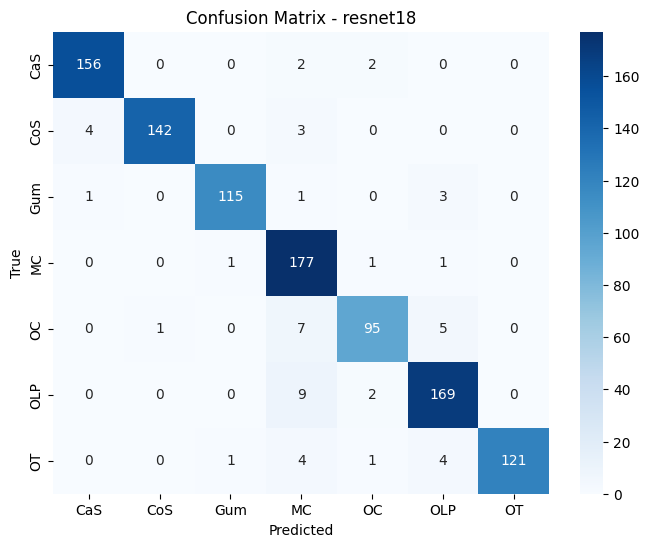

c:\Users\Eng.Razan\AppData\Local\Programs\Python\Python310\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\Eng.Razan\AppData\Local\Programs\Python\Python310\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)
C:\Users\Eng.Razan\AppData\Local\Temp\ipykernel_12528\46678176.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In


🔎 Evaluation for resnet50:
Accuracy: 0.9300
              precision    recall  f1-score   support

         CaS       0.92      0.98      0.95       160
         CoS       0.98      0.97      0.98       149
         Gum       0.91      0.94      0.93       120
          MC       0.97      0.86      0.91       180
          OC       0.86      0.96      0.91       108
         OLP       0.89      0.89      0.89       180
          OT       0.97      0.93      0.95       131

    accuracy                           0.93      1028
   macro avg       0.93      0.93      0.93      1028
weighted avg       0.93      0.93      0.93      1028



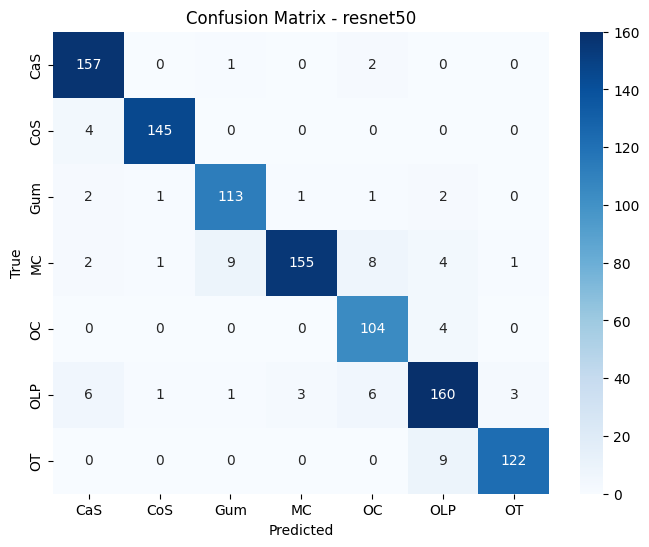

c:\Users\Eng.Razan\AppData\Local\Programs\Python\Python310\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\Eng.Razan\AppData\Local\Programs\Python\Python310\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)
C:\Users\Eng.Razan\AppData\Local\Temp\ipykernel_12528\46678176.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In


🔎 Evaluation for mobilenet_v2:
Accuracy: 0.9640
              precision    recall  f1-score   support

         CaS       0.99      0.98      0.99       160
         CoS       0.97      0.99      0.98       149
         Gum       0.94      0.99      0.96       120
          MC       0.97      0.93      0.95       180
          OC       0.93      0.95      0.94       108
         OLP       0.98      0.94      0.96       180
          OT       0.95      0.97      0.96       131

    accuracy                           0.96      1028
   macro avg       0.96      0.97      0.96      1028
weighted avg       0.96      0.96      0.96      1028



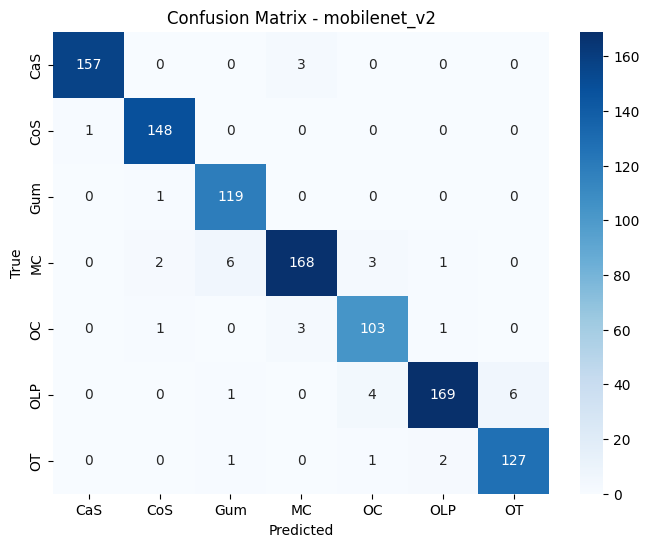

c:\Users\Eng.Razan\AppData\Local\Programs\Python\Python310\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\Eng.Razan\AppData\Local\Programs\Python\Python310\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)
C:\Users\Eng.Razan\AppData\Local\Temp\ipykernel_12528\46678176.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In


🔎 Evaluation for efficientnet_b0:
Accuracy: 0.9844
              precision    recall  f1-score   support

         CaS       0.99      0.99      0.99       160
         CoS       1.00      0.98      0.99       149
         Gum       1.00      0.98      0.99       120
          MC       0.96      0.99      0.98       180
          OC       0.96      0.99      0.98       108
         OLP       0.99      0.97      0.98       180
          OT       0.99      0.99      0.99       131

    accuracy                           0.98      1028
   macro avg       0.99      0.98      0.98      1028
weighted avg       0.98      0.98      0.98      1028



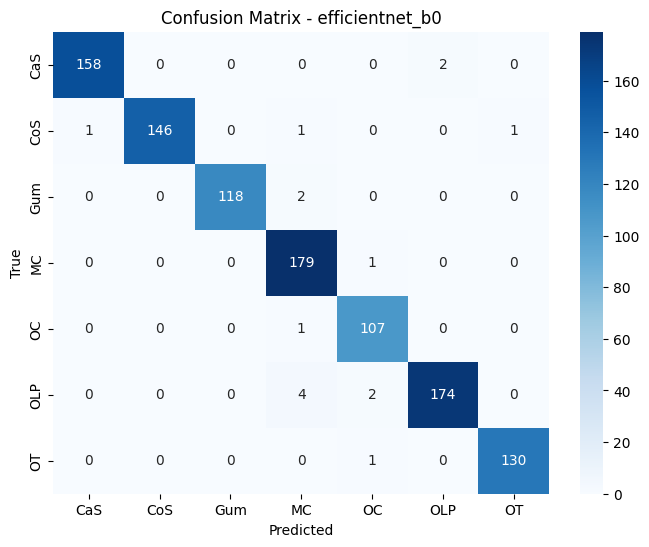

c:\Users\Eng.Razan\AppData\Local\Programs\Python\Python310\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\Eng.Razan\AppData\Local\Programs\Python\Python310\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)
C:\Users\Eng.Razan\AppData\Local\Temp\ipykernel_12528\46678176.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In


🔎 Evaluation for densenet121:
Accuracy: 0.9689
              precision    recall  f1-score   support

         CaS       0.98      0.99      0.99       160
         CoS       0.99      0.99      0.99       149
         Gum       0.97      1.00      0.98       120
          MC       0.95      0.98      0.96       180
          OC       0.96      0.97      0.97       108
         OLP       0.98      0.93      0.95       180
          OT       0.96      0.92      0.94       131

    accuracy                           0.97      1028
   macro avg       0.97      0.97      0.97      1028
weighted avg       0.97      0.97      0.97      1028



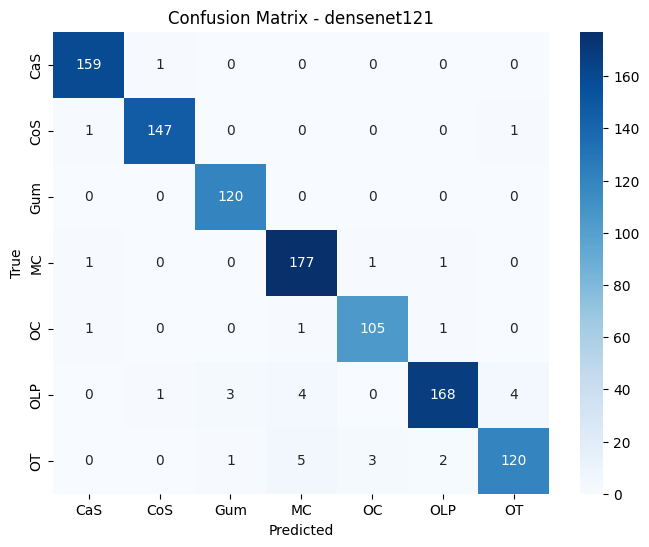

In [14]:
results = {}

results["resnet18"] = evaluate_model("resnet18", "resnet18_best.pth", test_dataset, test_loader)
results["resnet50"] = evaluate_model("resnet50", "resnet50_best.pth", test_dataset, test_loader)
results["mobilenet_v2"] = evaluate_model("mobilenet_v2", "mobilenet_v2_best.pth", test_dataset, test_loader)
results["efficientnet_b0"] = evaluate_model("efficientnet_b0", "efficientnet_b0_best.pth", test_dataset, test_loader)
results["densenet121"] = evaluate_model("densenet121", "densenet121_best.pth", test_dataset, test_loader)


## Visual Comparison (Bar Chart)

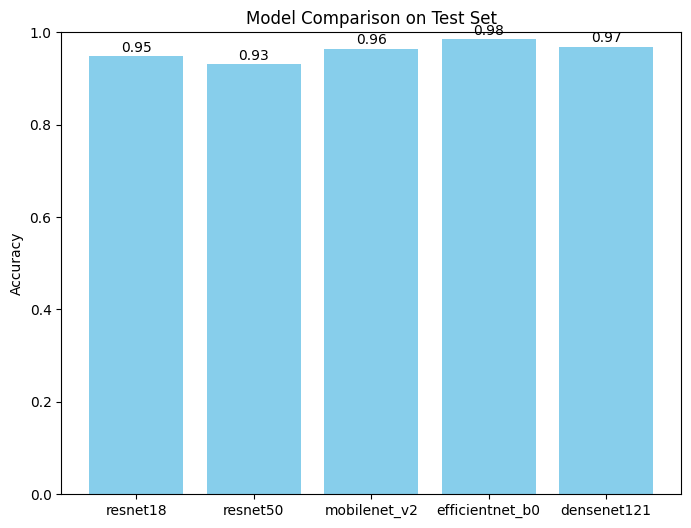

In [15]:
plt.figure(figsize=(8,6))
plt.bar(results.keys(), results.values(), color="skyblue")
plt.ylabel("Accuracy")
plt.title("Model Comparison on Test Set")
plt.ylim(0,1)
for i, v in enumerate(results.values()):
    plt.text(i, v+0.01, f"{v:.2f}", ha="center", fontsize=10)
plt.show()
